In [29]:
import pandas as pd
import numpy as np

athletes = pd.read_csv("../data/athlete_events.csv")
regions = pd.read_csv("../data/noc_regions.csv")

df = athletes.merge(regions, on="NOC", how="left")

df = df[df["Season"] == "Summer"].copy()

def country_group(row):
    if row["NOC"] == "USA":
        return "United States"
    elif row["NOC"] in ["RUS", "URS", "EUN"]:
        return "Russia/USSR"
    elif row["NOC"] == "CHN":
        return "China"
    else:
        return "Other"

df["country_group"] = df.apply(country_group, axis=1)

df = df[df["country_group"].isin(["United States", "Russia/USSR", "China"])]

df["medaled"] = df["Medal"].notna().astype(int)

In [30]:
panel = (
    df.groupby(["Year", "Sport", "country_group"])["medaled"]
    .sum()
    .reset_index()
)

panel["won_any_medal"] = (panel["medaled"] > 0).astype(int)

panel = panel.sort_values(["country_group", "Sport", "Year"])
panel["prior_medals"] = (
    panel.groupby(["country_group", "Sport"])["medaled"]
    .shift(1)
    .fillna(0)
)

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X = panel[["Year", "Sport", "country_group", "prior_medals"]]
y = panel["won_any_medal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=3120, stratify=y
)

preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["Sport", "country_group"]),
        ("num", "passthrough", ["Year", "prior_medals"])
    ]
)

model = Pipeline([
    ("prep", preprocess),
    ("logit", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, pred))
print("AUC:", roc_auc_score(y_test, prob))

Accuracy: 0.724025974025974
AUC: 0.7708940719144801


/Users/leoqian/ORIE3120/ORIE3120-Group18/venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


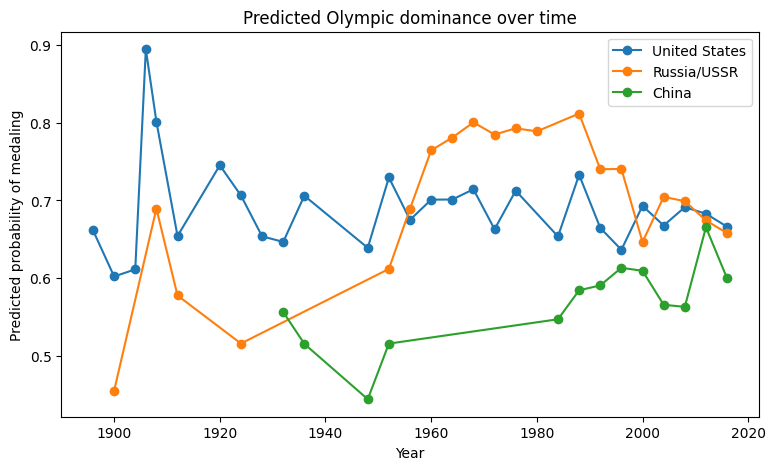

In [32]:
panel["predicted_prob"] = model.predict_proba(X)[:, 1]

trend = (
    panel.groupby(["Year", "country_group"])["predicted_prob"]
    .mean()
    .reset_index()
)

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
for country in trend["country_group"].unique():
    temp = trend[trend["country_group"] == country]
    plt.plot(temp["Year"], temp["predicted_prob"], marker="o", label=country)

plt.xlabel("Year")
plt.ylabel("Predicted probability of medaling")
plt.title("Predicted Olympic dominance over time")
plt.legend()
plt.show()

In [34]:
feature_names = model.named_steps["prep"].get_feature_names_out()
coefficients = model.named_steps["logit"].coef_[0]

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
}).sort_values(by="coefficient", ascending=False)

print(coef_df.head(10))
print(coef_df.tail(10))

                     feature  coefficient
28       cat__Sport_Shooting     1.630143
41      cat__Sport_Wrestling     1.377712
33      cat__Sport_Taekwondo     1.162018
24         cat__Sport_Rowing     1.011618
7          cat__Sport_Boxing     0.956793
20           cat__Sport_Judo     0.780873
40  cat__Sport_Weightlifting     0.780389
10         cat__Sport_Diving     0.770761
25          cat__Sport_Rugby     0.707920
22           cat__Sport_Polo     0.571768
                           feature  coefficient
26         cat__Sport_Rugby Sevens    -0.555389
23  cat__Sport_Rhythmic Gymnastics    -0.698377
3             cat__Sport_Badminton    -0.746990
21    cat__Sport_Modern Pentathlon    -0.776015
14             cat__Sport_Football    -1.015442
39           cat__Sport_Water Polo    -1.162160
17             cat__Sport_Handball    -1.171249
32         cat__Sport_Table Tennis    -1.312524
18               cat__Sport_Hockey    -1.407652
36            cat__Sport_Triathlon    -1.483216
